<a href="https://colab.research.google.com/github/ayeshaazahidd0-stack/Digital-Image-Processing/blob/main/Noise_Denoise_L5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Upload One Image (Simple Colab Upload)**

In [5]:
from google.colab import files
uploaded = files.upload() # pick a single file
print("Uploaded:", list(uploaded.keys()))
# Use the first (or only) uploaded file as our image
keys = list(uploaded.keys())
if len(keys) == 0:
   raise RuntimeError("Please upload one image.")
IMG = keys[0]
print("Using image:", IMG)

Saving adad.jpg to adad.jpg
Uploaded: ['adad.jpg']
Using image: adad.jpg


**Setup & Helper Functions (Run Once)**

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(img, title="", size=5, cmap=None):
    """Display an image nicely with a title."""
    plt.figure(figsize=(size, size))
    if img.ndim == 2:
        plt.imshow(img, cmap=cmap if cmap else "gray")
    else:
        plt.imshow(img)
    plt.title(title)
    plt.axis("off")
    plt.show()

def imread_rgb(path):
    """Read an image (BGR) with OpenCV and convert to RGB for plotting."""
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(f"Could not read {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# Load the single image
I = imread_rgb(IMG)

# Fix randomness so class results look similar each run
np.random.seed(0)

# ---- Noise functions ----
def add_gaussian_noise(img, sigma=15.0):
    """Add Gaussian (normal) noise with std-dev = sigma to each pixel."""
    noise = np.random.normal(0, sigma, img.shape).astype(np.float32)
    out = img.astype(np.float32) + noise
    return np.clip(out, 0, 255).astype(np.uint8)

def add_salt_pepper(img, amount=0.02, s_vs_p=0.5):
    """Flip a fraction of pixels to 255 (salt) and 0 (pepper)."""
    out = img.copy()
    H, W = img.shape[:2]
    N = int(amount * H * W)
    # salt (white)
    ys = np.random.randint(0, H, int(N * s_vs_p))
    xs = np.random.randint(0, W, int(N * s_vs_p))
    out[ys, xs] = 255
    # pepper (black)
    ys = np.random.randint(0, H, N - int(N * s_vs_p))
    xs = np.random.randint(0, W, N - int(N * s_vs_p))
    out[ys, xs] = 0
    return out

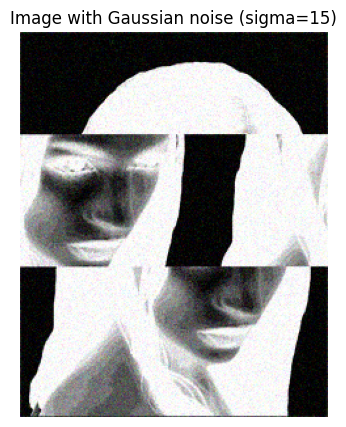

In [14]:
# sigma controls noise strength: start with 15.
I_g = add_gaussian_noise(I, sigma=15)
show(I_g, "Image with Gaussian noise (sigma=15)")

TASK 2-Add Salt-and-Pepper noise ( white/black specks)

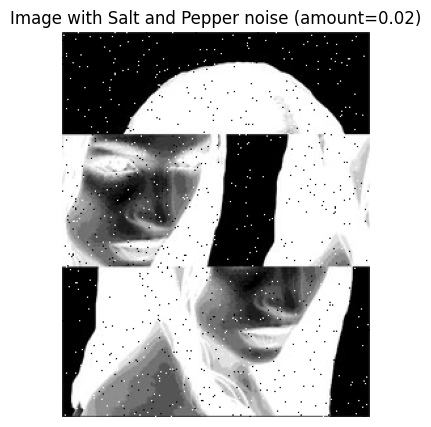

In [10]:
#amount is fraction of pixels flipped: start with 0.02(2%)
I_sp = add_salt_pepper(I, amount=0.02)
show(I_sp, "Image with Salt and Pepper noise (amount=0.02)")

Task 3 -- Smooth Guassian-noisy image using Mean filter (cv2.blur)


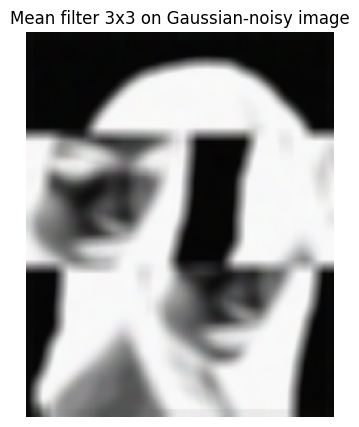

In [19]:
# Mean filter averages pixels in a window. It smooths noise but also blurs edges.
I_g_mean3 = cv2.blur(I_g, (11, 11))
show(I_g_mean3, "Mean filter 3x3 on Gaussian-noisy image")

**Task 4 - Smooth Guassian-noisy image using Gaussian blur**

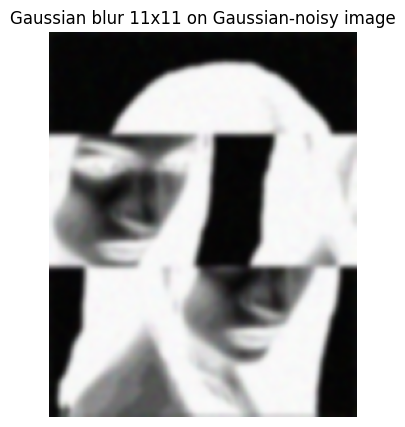

In [24]:
# Gaussian blur matches Gaussian noise better than mean blur (usually better results)
I_g_gb5 = cv2.GaussianBlur(I_g, (11, 11), 0)
show(I_g_gb5, "Gaussian blur 11x11 on Gaussian-noisy image")

**Task 6 -- Smooth  S&P - noisy image using Median filter**

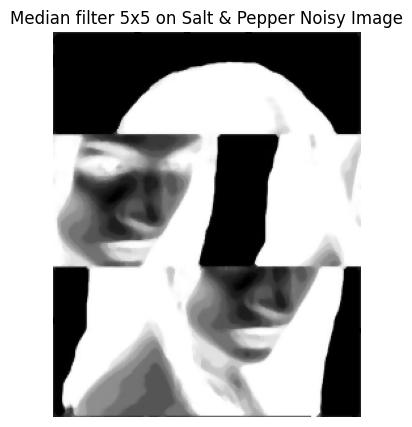

In [23]:
# Median filter is highly effective at removing salt-and-pepper noise
I_sp_median = cv2.medianBlur(I_sp, 5)
show(I_sp_median, "Median filter 5x5 on Salt & Pepper Noisy Image")

**Apply on salt and pepperr**

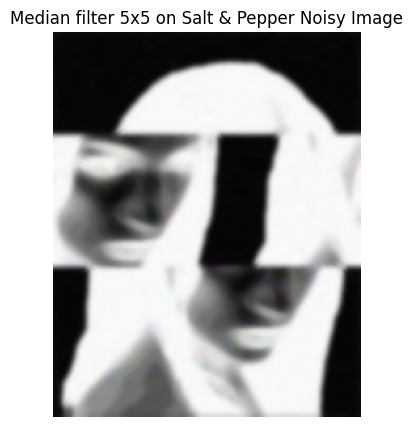

In [26]:
# Median filter is highly effective at removing salt-and-pepper noise
I_sp_mean = cv2.medianBlur(I_sp, 5)
show(I_sp_mean, "Median filter 5x5 on Salt & Pepper Noisy Image")
#it removes isolated white/black specks and preserves edges better

Task 9: Explore